In [1]:
pip install pandas matplotlib seaborn openpyxl

In [2]:
import pandas as pd
from pathlib import Path

DATA = Path("data")

products = pd.read_csv(DATA / "/content/products.csv")
inv      = pd.read_csv(DATA / "/content/inventory_master.csv")
lines    = pd.read_csv(DATA / "/content/sales_orders_lines.csv")
ledger   = pd.read_csv(DATA / "/content/stock_ledger.csv")

tables = {
    "products": products,
    "inventory_master": inv,
    "sales_orders_lines": lines,
    "stock_ledger": ledger,
}

# Day 1: profile every table
for name, df in tables.items():
    print(f"\n==== {name} ====")
    print("shape:", df.shape)
    print("columns:", list(df.columns))
    print("dtypes:\n", df.dtypes)
    nulls = df.isna().sum()
    print("nulls:\n", nulls[nulls > 0] if (nulls > 0).any() else "none")
    print("duplicate rows:", df.duplicated().sum())


==== products ====
shape: (30, 23)
columns: ['product_id', 'product_name', 'category', 'machine_type', 'brand', 'model_compatibility', 'unit_cost', 'unit_price', 'margin_percentage', 'gst_rate', 'weight_kg', 'dimensions_cm', 'material_type', 'warranty_months', 'reorder_level', 'safety_stock', 'max_stock_level', 'lead_time_days', 'criticality_level', 'usage_frequency', 'uom', 'last_purchase_price', 'last_purchase_date']
dtypes:
 product_id              object
product_name            object
category                object
machine_type            object
brand                   object
model_compatibility     object
unit_cost                int64
unit_price               int64
margin_percentage      float64
gst_rate                 int64
weight_kg              float64
dimensions_cm           object
material_type           object
warranty_months          int64
reorder_level            int64
safety_stock             int64
max_stock_level          int64
lead_time_days           int64
criticali

In [6]:
!find . -name "*.py"

day 2


In [8]:
import pandas as pd
from pathlib import Path

DATA = Path("data")
OUT = Path("week-04/output")
OUT.mkdir(parents=True, exist_ok=True)

# >>> Edit these to match your CSV headers <<<
PID   = "product_id"    # product key, in both files
QTY   = "quantity"      # units on the sales line
PRICE = "unit_price"    # selling price per unit on the line
COST  = "unit_cost"     # cost per unit (from products.csv)
NAME  = "product_name"  # display name (from products.csv)

products = pd.read_csv(DATA / "/content/products.csv")
lines    = pd.read_csv(DATA / "/content/sales_orders_lines.csv")

# Assumption: drop zero/negative quantities (returns handled separately later)
lines = lines[lines[QTY] > 0].copy()

# Attach cost and calculate line-level revenue and COGS
lines = lines.merge(products[[PID, COST]], on=PID, how="left")
lines["revenue"] = lines[QTY] * lines[PRICE]
lines["cogs"]    = lines[QTY] * lines[COST]

# Aggregate per product
perf = (
    lines.groupby(PID)
    .agg(units=(QTY, "sum"),
         revenue=("revenue", "sum"),
         cogs=("cogs", "sum"),
         sales_lines=(QTY, "size"))
    .reset_index()
)
perf["gross_margin"]     = perf["revenue"] - perf["cogs"]
perf["gross_margin_pct"] = (perf["gross_margin"] / perf["revenue"] * 100).round(1)

perf = perf.merge(products[[PID, NAME]], on=PID, how="left")
perf = perf.sort_values("revenue", ascending=False)
perf["revenue_rank"] = range(1, len(perf) + 1)
perf["units_rank"]   = perf["units"].rank(ascending=False, method="min").astype(int)

perf.to_csv(OUT / "product_performance.csv", index=False)

# Top 20 by revenue vs by units: where do they disagree?
top_rev   = set(perf.nlargest(20, "revenue")[PID])
top_units = set(perf.nlargest(20, "units")[PID])
print("Top 20 by revenue:", len(top_rev))
print("In top 20 revenue but not units:", len(top_rev - top_units))
print("In top 20 units but not revenue:", len(top_units - top_rev))

print("\nTop 10 by revenue:")
print(perf.head(10)[[NAME, "units", "revenue", "gross_margin_pct"]].to_string(index=False))

Top 20 by revenue: 20
In top 20 revenue but not units: 7
In top 20 units but not revenue: 7

Top 10 by revenue:
                product_name  units    revenue  gross_margin_pct
         Engine Block EB-600  45222 5381418000              19.7
Transmission Assembly TA-800  45035 3760422500              18.0
        Boom Cylinder BC-400  46364 2142016800              22.9
         Swing Motor SWM-350  45971 1829645800              21.6
           Track Chain TC-45  45575 1813885000              18.3
         Turbocharger TB-900  46964 1639043600              17.2
   Hydraulic Cylinder HC-200  46612 1286491200              22.1
       Hydraulic Pump HP-300  45389 1112030500              22.7
            Fuel Pump FP-350  45897 1005144300              25.1
         Control Valve CV-75  45819  774341100              24.3


In [10]:
!python week-04/week04_day2.py

python3: can't open file '/content/week-04/week04_day2.py': [Errno 2] No such file or directory


day 3


In [15]:
import pandas as pd
from pathlib import Path

DATA = Path("/content")
OUT = Path("week-04/output")
OUT.mkdir(parents=True, exist_ok=True)

# >>> Updated configuration to match your CSV headers <<<
PID        = "product_id"
ORDER_ID   = "so_id"             # changed from "order_id" to "so_id"
ORDER_DATE = "order_date"
QTY        = "quantity"
ON_HAND    = "current_stock"     # changed from "quantity_on_hand" to "current_stock"
DEAD_DAYS  = 90                   # assumption: no sales in this many days = dead stock

perf    = pd.read_csv(OUT / "/content/week-04/output/product_performance.csv")
lines   = pd.read_csv(DATA / "/content/sales_orders_lines.csv")
headers = pd.read_csv(DATA / "/content/sales_orders_header.csv", parse_dates=[ORDER_DATE])
inv     = pd.read_csv(DATA / "/content/inventory_master.csv")

# Period length, from the sales data itself
start, end = headers[ORDER_DATE].min(), headers[ORDER_DATE].max()
period_days = (end - start).days + 1
print(f"Sales period: {start.date()} to {end.date()} ({period_days} days)")

# Last sale date per product
lines = lines.merge(headers[[ORDER_ID, ORDER_DATE]], on=ORDER_ID, how="left")
last_sale = (lines.groupby(PID)[ORDER_DATE].max()
             .rename("last_sale_date").reset_index())

# Velocity: units per day over the period
df = perf.merge(last_sale, on=PID, how="left")
df["velocity_per_day"] = df["units"] / period_days

# Stock on hand per product
stock = inv.groupby(PID)[ON_HAND].sum().rename("on_hand").reset_index()
df = df.merge(stock, on=PID, how="left")
df["on_hand"] = df["on_hand"].fillna(0)

# Fast / slow classification by velocity percentile
# Products with no sales at all are classed as "non-moving"
sold = df["units"] > 0
p80 = df.loc[sold, "velocity_per_day"].quantile(0.80)
p20 = df.loc[sold, "velocity_per_day"].quantile(0.20)

def classify(row):
    if row["units"] == 0:
        return "non-moving"
    if row["velocity_per_day"] >= p80:
        return "fast"
    if row["velocity_per_day"] <= p20:
        return "slow"
    return "medium"

df["movement_class"] = df.apply(classify, axis=1)

# Dead stock: stock on hand, but no sale in the last DEAD_DAYS
cutoff = end - pd.Timedelta(days=DEAD_DAYS)
df["dead_stock"] = (df["on_hand"] > 0) & (
    df["last_sale_date"].isna() | (pd.to_datetime(df["last_sale_date"]) < cutoff))

df.to_csv(OUT / "movement_classification.csv", index=False)

# Summary
print("\nMovement class counts:")
print(df["movement_class"].value_counts().to_string())
print(f"\nThresholds: fast >= {p80:.2f} units/day, slow <= {p20:.2f} units/day")
print(f"Dead stock products: {df["dead_stock"].sum()}")
print(f"Units on hand in dead stock: {df.loc[df["dead_stock"], "on_hand"].sum():,.0f}")

print("\nTop 10 fast movers:")
print(df[df["movement_class"] == "fast"]
      .nlargest(10, "velocity_per_day")[["product_name", "velocity_per_day", "revenue"]
      ].to_string(index=False))

Sales period: 2019-01-01 to 2024-12-31 (2192 days)

Movement class counts:
movement_class
medium    18
fast       6
slow       6

Thresholds: fast >= 21.13 units/day, slow <= 20.54 units/day
Dead stock products: 0
Units on hand in dead stock: 0

Top 10 fast movers:
             product_name  velocity_per_day    revenue
    Pressure Sensor PS-90         21.471715  185910700
      Turbocharger TB-900         21.425182 1639043600
       Alternator ALT-500         21.318887  523387200
Hydraulic Cylinder HC-200         21.264599 1286491200
     Hydraulic Hose HH-60         21.198905   67378600
     Boom Cylinder BC-400         21.151460 2142016800


In [14]:
!python week-04/week04_day3.py

python3: can't open file '/content/week-04/week04_day3.py': [Errno 2] No such file or directory


day 4

In [17]:
import pandas as pd
from pathlib import Path

DATA = Path("/content")
OUT = Path("week-04/output")

# >>> Updated to match your actual CSV headers <<<
PID       = "product_id"
UNIT_COST = "unit_cost"           # from products.csv
ON_HAND   = "current_stock"       # changed from "quantity_on_hand" to "current_stock"

# Assumptions: write these in your sprint notes
OVERSTOCK_DAYS  = 90   # days of cover above this = overstock
UNDERSTOCK_DAYS = 7    # days of cover below this = understock (use your lead time if known)

df = pd.read_csv(OUT / "movement_classification.csv")
products = pd.read_csv(DATA / "products.csv")
inv = pd.read_csv(DATA / "inventory_master.csv")

# Recovered the period length from Day 3's output: 2192 days (2019-01-01 to 2024-12-31)
period_days = 2192

# Current stock value at cost
stock = inv.groupby(PID)[ON_HAND].sum().rename("on_hand").reset_index()
stock = stock.merge(products[[PID, UNIT_COST]], on=PID, how="left")
stock["stock_value"] = stock["on_hand"] * stock[UNIT_COST]

df = df.drop(columns=["on_hand"], errors="ignore").merge(stock, on=PID, how="left")
df[["on_hand", "stock_value"]] = df[["on_hand", "stock_value"]].fillna(0)

# Total COGS and average inventory value
# Proxy: the current snapshot stands in for average inventory (see note below)
total_cogs = df["cogs"].sum()
avg_inventory_value = df["stock_value"].sum()
turnover = total_cogs / avg_inventory_value if avg_inventory_value else float("nan")

days_of_inventory = period_days / turnover if turnover else float("nan")

print(f"Total COGS: {total_cogs:,.0f}")
print(f"Stock value (snapshot): {avg_inventory_value:,.0f}")
print(f"Inventory turnover: {turnover:.2f}x")
print(f"Days of inventory: {days_of_inventory:.0f}")

# Product-level days of cover = on-hand units / average daily units sold
df["daily_units"] = df["velocity_per_day"]
df["days_of_cover"] = df["on_hand"] / df["daily_units"].replace(0, pd.NA)

def stock_health(row):
    if row["on_hand"] == 0:
        return "out of stock"
    if pd.isna(row["days_of_cover"]):
        return "no sales"
    if row["days_of_cover"] > OVERSTOCK_DAYS:
        return "overstock"
    if row["days_of_cover"] < UNDERSTOCK_DAYS:
        return "understock"
    return "healthy"

df["stock_health"] = df.apply(stock_health, axis=1)

df.to_csv(OUT / "stock_health.csv", index=False)

# Summaries for the sprint notes and charts
print("\nStock health counts:")
print(df["stock_health"].value_counts().to_string())

print("\nStock value by health status:")
print(df.groupby("stock_health")["stock_value"].sum().round(0).to_string())

print("\nTop 10 overstock by stock value:")
print(df[df["stock_health"] == "overstock"]
      .nlargest(10, "stock_value")[["product_name", "on_hand", "days_of_cover", "stock_value"]
      ].to_string(index=False))

Total COGS: 19,961,848,170
Stock value (snapshot): 281,292,677,410
Inventory turnover: 0.07x
Days of inventory: 30889

Stock health counts:
stock_health
overstock    30

Stock value by health status:
stock_health
overstock    281292677410

Top 10 overstock by stock value:
                product_name  on_hand  days_of_cover  stock_value
         Engine Block EB-600   632583   30662.552209  60411676500
Transmission Assembly TA-800   661663   32205.291351  45323915500
        Boom Cylinder BC-400   630617   29814.348719  22449965200
           Track Chain TC-45   638882   30728.016325  20763665000
         Swing Motor SWM-350   622249   29670.222706  19414168800
         Turbocharger TB-900   661248   30863.121029  19110067200
   Hydraulic Cylinder HC-200   650389   30585.529220  13983363500
       Hydraulic Pump HP-300   643984   31100.331093  12203496800
            Fuel Pump FP-350   632290   30197.609430  10369556000
         Control Valve CV-75   647348   30969.397324   8286054400


In [19]:
!python week-04/week04_day4.py

python3: can't open file '/content/week-04/week04_day4.py': [Errno 2] No such file or directory


day 5

In [20]:
from pathlib import Path
for f in ["product_performance.csv", "movement_classification.csv", "stock_health.csv"]:
    p = Path("/content/week-04/output") / f
    print(f, "exists" if p.exists() else "MISSING")

product_performance.csv exists
movement_classification.csv exists
stock_health.csv exists


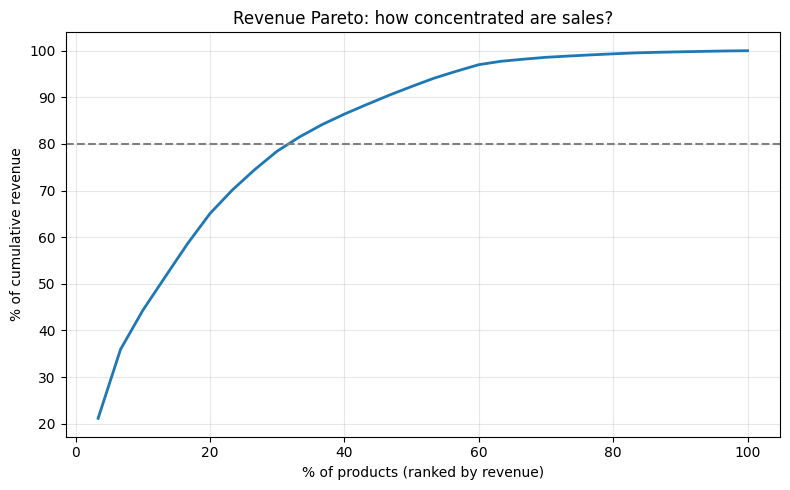

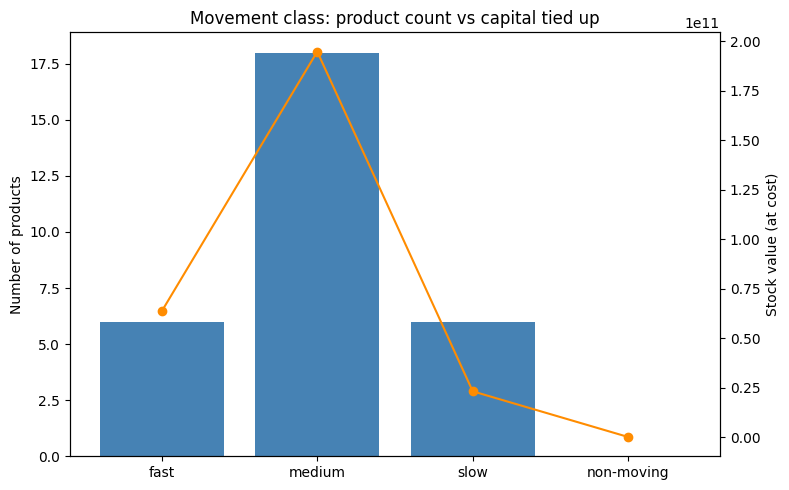

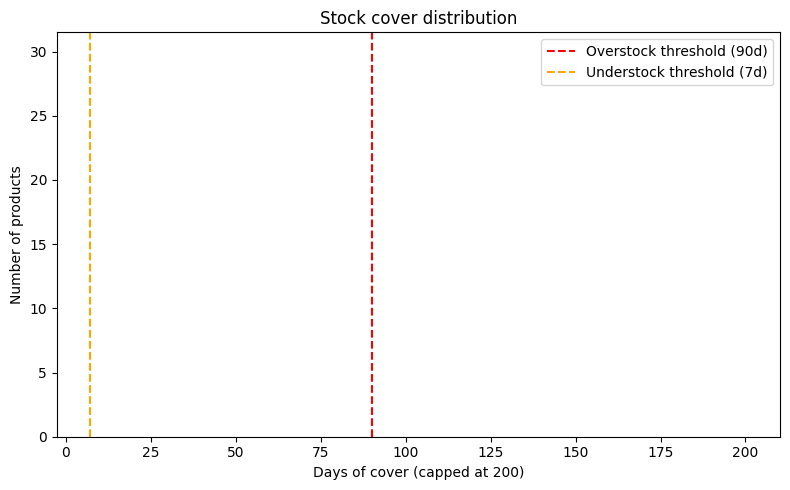

                                       value
Products with sales                       30
Total products                            30
Revenue (total)                  25447392560
Gross margin %                          21.6
Stock value (snapshot)          281292677410
Overstock value                 281292677410
Overstock products                        30
Dead stock value                           0
Dead stock products                        0
Products making 80% of revenue    10 (33.3%)
Saved to /content/week-04/output


In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

OUT = Path("/content/week-04/output")
OUT.mkdir(parents=True, exist_ok=True)

PID  = "product_id"
NAME = "product_name"

df = pd.read_csv(OUT / "stock_health.csv")
perf = pd.read_csv(OUT / "product_performance.csv")

# Chart 1: Pareto curve of revenue
pareto = perf.sort_values("revenue", ascending=False).reset_index(drop=True)
pareto["cum_share"] = pareto["revenue"].cumsum() / pareto["revenue"].sum() * 100
pareto["product_share"] = (pareto.index + 1) / len(pareto) * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pareto["product_share"], pareto["cum_share"], linewidth=2)
ax.axhline(80, linestyle="--", color="grey")
ax.set_xlabel("% of products (ranked by revenue)")
ax.set_ylabel("% of cumulative revenue")
ax.set_title("Revenue Pareto: how concentrated are sales?")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(OUT / "chart1_pareto_revenue.png", dpi=150)
plt.show()

share_80 = pareto.loc[pareto["cum_share"] >= 80].index[0] + 1
pct_80 = share_80 / len(pareto) * 100

# Chart 2: movement class, product count vs stock value
mv = df.groupby("movement_class").agg(
    products=(PID, "size"),
    stock_value=("stock_value", "sum")).reindex(
    ["fast", "medium", "slow", "non-moving"]).fillna(0)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.bar(mv.index, mv["products"], color="steelblue", label="Products")
ax1.set_ylabel("Number of products")
ax2 = ax1.twinx()
ax2.plot(mv.index, mv["stock_value"], color="darkorange", marker="o", label="Stock value")
ax2.set_ylabel("Stock value (at cost)")
ax1.set_title("Movement class: product count vs capital tied up")
fig.tight_layout()
fig.savefig(OUT / "chart2_movement_class.png", dpi=150)
plt.show()

# Chart 3: days-of-cover histogram
cover = pd.to_numeric(df["days_of_cover"], errors="coerce").dropna()
fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(cover.clip(upper=200), bins=40, color="seagreen", edgecolor="white")
ax.axvline(90, linestyle="--", color="red", label="Overstock threshold (90d)")
ax.axvline(7, linestyle="--", color="orange", label="Understock threshold (7d)")
ax.set_xlabel("Days of cover (capped at 200)")
ax.set_ylabel("Number of products")
ax.set_title("Stock cover distribution")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "chart3_days_of_cover.png", dpi=150)
plt.show()

# KPI summary
overstock = df[df["stock_health"] == "overstock"]
dead = df[df["dead_stock"] == True]
kpis = {
    "Products with sales": int((df["units"] > 0).sum()),
    "Total products": len(df),
    "Revenue (total)": round(df["revenue"].sum(), 0),
    "Gross margin %": round(df["gross_margin"].sum() / df["revenue"].sum() * 100, 1),
    "Stock value (snapshot)": round(df["stock_value"].sum(), 0),
    "Overstock value": round(overstock["stock_value"].sum(), 0),
    "Overstock products": len(overstock),
    "Dead stock value": round(dead["stock_value"].sum(), 0),
    "Dead stock products": len(dead),
    "Products making 80% of revenue": f"{share_80} ({pct_80:.1f}%)",
}
kpi_df = pd.Series(kpis, name="value").to_frame()
kpi_df.to_csv(OUT / "week04_kpis.csv")
print(kpi_df.to_string())

overstock.nlargest(10, "stock_value")[[NAME, "on_hand", "days_of_cover", "stock_value"]].to_csv(
    OUT / "top10_overstock.csv", index=False)
print("Saved to", OUT)

In [22]:
import shutil
from google.colab import files
shutil.make_archive("/content/week04_outputs", "zip", "/content/week-04/output")
files.download("/content/week04_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [23]:
lines = pd.read_csv("/content/sales_orders_lines.csv")
inv = pd.read_csv("/content/inventory_master.csv")
print("Total units sold (6 years):", lines["quantity"].sum())
print("Total current stock:", inv["current_stock"].sum())
print("Total opening stock:", inv["opening_stock"].sum())

Total units sold (6 years): 1368534
Total current stock: 19303266
Total opening stock: 32969
